In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [2]:
class AgentState(TypedDict):
    number1: int
    operation: str
    number2: int
    finalNumber: int

In [4]:
def adder(state: AgentState)-> AgentState:
    """This node adds 2 numbers"""
    state["finalNumber"] = state["number1"] + state["number2"]
    return state

def subtractor(state: AgentState)-> AgentState:
    """This node subtracts 2 numbers"""
    state["finalNumber"] = state["number1"] - state["number2"]
    return state

def multiplier(state: AgentState)-> AgentState:
    """This node multiplies 2 numbers"""
    state["finalNumber"] = state["number1"] * state["number2"]
    return state

def decide_next_node(state:AgentState) -> AgentState:
    """This node does routing to next node"""

    if state["operation"] == "+":
        return "addition_operation"
    elif state["operation"] == "-":
        return "subtraction_operation"
    elif state["operation"] == "*":
        return "multiplication_operation"

In [7]:
graph = StateGraph(AgentState)

graph.add_node("adder_node", adder)
graph.add_node("subtractor_node", subtractor)
graph.add_node("multiplier_node", multiplier)

#decide_next_node --> return edges..not the updated state
#lambda state:state --> says tat the input same is same as the output state
#essentially a pass-through function
graph.add_node("router_node", lambda state:state)

graph.add_edge(START, "router_node")
graph.add_conditional_edges(
    "router_node", #source
    decide_next_node, #path
    {
        #dict  - edge:node
        "addition_operation": "adder_node",
        "subtraction_operation": "subtractor_node",
        "multiplication_operation": "multiplier_node",
    }
)

graph.add_edge("adder_node", END)
graph.add_edge("subtractor_node", END)
graph.add_edge("multiplier_node", END)

app = graph.compile()



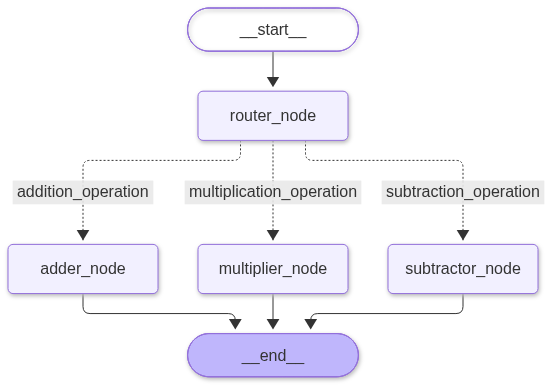

In [8]:
import IPython
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [10]:
initial_state_1 = AgentState(number1 = 10, operation="-",number2=5)
print(app.invoke(initial_state_1))

{'number1': 10, 'operation': '-', 'number2': 5, 'finalNumber': 5}
